In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Base Class & PDA

In [3]:
import numpy as np
import matplotlib.pyplot as plt

class BaseClassifier:
    def validate(self, X_dev, y_dev):
        predictions = self.predict(X_dev)
        accuracy = np.mean(predictions == y_dev)

        print("Validation Accuracy:", accuracy)
        self.confusion_matrix(y_dev, predictions)

        return accuracy

    def confusion_matrix(self, y_true, y_pred):
        labels = np.unique(np.concatenate([y_true, y_pred]))

        matrix = np.zeros(
            (len(labels), len(labels)), dtype=int
        )

        for actual, predicted in zip(y_true, y_pred):
            i = np.where(labels == actual)[0][0]
            j = np.where(labels == predicted)[0][0]
            matrix[i, j] += 1

        print("Confusion Matrix:\n", matrix)

        plt.figure(figsize=(6, 5))
        plt.imshow(matrix, cmap="Blues")
        plt.colorbar()

        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)

        plt.xlabel("Predicted Label")
        plt.ylabel("Actual Label")
        plt.title("Confusion Matrix")

        for i in range(len(labels)):
            for j in range(len(labels)):
                plt.text(j, i, matrix[i, j],
                         ha="center", va="center")

        plt.show()

        accuracy = np.trace(matrix) / np.sum(matrix)
        print("Accuracy:", accuracy)

        return matrix

    def plot(self, X, y, title="Decision Boundary"):
        if X.shape[1] != 2:
            print("Plotting requires exactly 2 features.")
            return

        x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
        y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1

        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, 200),
            np.linspace(y_min, y_max, 200)
        )

        grid = np.c_[xx.ravel(), yy.ravel()]
        Z = self.predict(grid)
        Z = Z.reshape(xx.shape)

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
        plt.scatter(X[:, 0], X[:, 1], c=y,
                    edgecolors="black", cmap="viridis")

        plt.xlabel("Feature 1")
        plt.ylabel("Feature 2")
        plt.title(title)
        plt.show()

In [4]:
def split_data(X, y, seed=42):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        train_idx = []
        dev_idx = []
        test_idx = []

        for label in np.unique(y):
            idx = np.where(y == label)[0]

            n = len(idx)
            n_train = int(0.60 * n)
            n_dev = int(0.20 * n)

            train_idx.extend(idx[:n_train])
            dev_idx.extend(idx[n_train:n_train+n_dev])
            test_idx.extend(idx[n_train+n_dev:])

        train_idx = np.array(train_idx)
        dev_idx = np.array(dev_idx)
        test_idx = np.array(test_idx)

        return (
            X[train_idx], X[dev_idx], X[test_idx],
            y[train_idx], y[dev_idx], y[test_idx]
        )

In [5]:
import numpy as np
import matplotlib.pyplot as plt

class PCA:
    def __init__(self, k=2):
        self.n_components = k
        self.mean = None
        self.eigenvalues = None
        self.eigenvectors = None
        self.components = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        X_centered = X - self.mean
        cov_matrix = np.cov(X_centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        idx = np.argsort(eigenvalues)[::-1]
        self.eigenvalues = eigenvalues[idx]
        self.eigenvectors = eigenvectors[:, idx]
        self.components = self.eigenvectors[:, :self.n_components]
        return self

    def transform(self, X):
        X_centered = X - self.mean
        X_transformed = np.dot(X_centered, self.components)
        return X_transformed

    def plot_pca_2d(self, X, y=None):
        plt.figure(figsize=(8, 6))
        if y is None:
            plt.scatter(
                X[:, 0],
                X[:, 1],
                alpha=0.7
            )
        else:
            for label in np.unique(y):
                plt.scatter(
                    X[y == label, 0],
                    X[y == label, 1],
                    label=f"Class {label}",
                    alpha=0.7
                )

            plt.legend()

        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")
        plt.title("PCA - 2D Projection")
        plt.grid(True)
        plt.show()

##Classifier Classes

In [9]:
class GMMClassifier(BaseClassifier):

    def __init__(self, K=2, max_iter=100, tol=1e-4):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol

    def log_gaussian(self, X, mean, cov):
        d = X.shape[1]
        cov = cov + 1e-6 * np.eye(d)
        diff = X - mean
        sign, logdet = np.linalg.slogdet(cov)
        if sign <= 0:
            return np.full(len(X), -np.inf)
        inv = np.linalg.inv(cov)
        exponent = np.sum((diff @ inv) * diff, axis=1)
        return -0.5 * (
            d * np.log(2 * np.pi) + logdet + exponent
        )

    def logsumexp(self, A):
        m = np.max(A, axis=1, keepdims=True)
        return (m + np.log(np.sum(
            np.exp(A - m), axis=1, keepdims=True
        ))).ravel()

    def fit_gmm(self, X):
        n, d = X.shape
        rng = np.random.default_rng(42)
        means = X[rng.choice(n, self.K, replace=False)]
        covs = np.array([np.cov(X.T) + 1e-6*np.eye(d)
                         for _ in range(self.K)])
        weights = np.ones(self.K) / self.K
        previous_ll = -np.inf

        for _ in range(self.max_iter):

            log_prob = np.zeros((n, self.K))

            for k in range(self.K):
                log_prob[:, k] = (
                    np.log(weights[k] + 1e-12) +
                    self.log_gaussian(X, means[k], covs[k])
                )

            log_total = self.logsumexp(log_prob)
            responsibilities = np.exp(
                log_prob - log_total[:, None]
            )

            Nk = responsibilities.sum(axis=0) + 1e-10

            weights = Nk / n
            means = (responsibilities.T @ X) / Nk[:, None]

            for k in range(self.K):
                diff = X - means[k]
                covs[k] = (
                    (diff.T * responsibilities[:, k]) @ diff
                    / Nk[k]
                )
                covs[k] += 1e-6 * np.eye(d)

            current_ll = np.sum(log_total)

            if abs(current_ll - previous_ll) < self.tol:
                break

            previous_ll = current_ll

        return weights, means, covs

    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)
        self.models = {}

        for label in self.classes:
            X_class = X_train[y_train == label]
            self.models[label] = self.fit_gmm(X_class)

    def predict(self, X):
        scores = []

        for label in self.classes:
            weights, means, covs = self.models[label]

            component_scores = []

            for k in range(self.K):
                component_scores.append(
                    np.log(weights[k] + 1e-12) +
                    self.log_gaussian(X, means[k], covs[k])
                )

            scores.append(
                self.logsumexp(np.column_stack(component_scores))
            )

        scores = np.column_stack(scores)
        return self.classes[np.argmax(scores, axis=1)]

In [10]:
class LDAClassifier(BaseClassifier):

    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)
        n, d = X_train.shape

        self.means = []
        self.priors = []

        covariance = np.zeros((d, d))

        for label in self.classes:
            X_class = X_train[y_train == label]

            mean = np.mean(X_class, axis=0)
            self.means.append(mean)

            self.priors.append(len(X_class) / n)

            diff = X_class - mean
            covariance += diff.T @ diff

        self.means = np.array(self.means)
        self.priors = np.array(self.priors)

        covariance /= (n - len(self.classes))
        covariance += 1e-6 * np.eye(d)

        self.inv_cov = np.linalg.pinv(covariance)

    def predict(self, X):
        scores = []

        for i in range(len(self.classes)):
            mean = self.means[i]

            score = (
                X @ self.inv_cov @ mean
                - 0.5 * mean @ self.inv_cov @ mean
                + np.log(self.priors[i])
            )

            scores.append(score)

        scores = np.column_stack(scores)

        return self.classes[np.argmax(scores, axis=1)]

In [11]:

class KNNClassifier(BaseClassifier):

    def __init__(self, K=5):
        self.K = K

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=float)
        self.y_train = np.asarray(y_train)

    def predict(self, X):
        predictions = []

        for sample in X:
            distances = np.sqrt(
                np.sum((self.X_train - sample)**2, axis=1)
            )

            nearest = np.argsort(distances)[:self.K]

            labels = self.y_train[nearest]
            unique, counts = np.unique(
                labels, return_counts=True
            )

            predictions.append(unique[np.argmax(counts)])

        return np.array(predictions)

In [12]:
class SVMClassifier(BaseClassifier):

    def __init__(self, lr=0.001, epochs=1000, C=1.0):
        self.lr = lr
        self.epochs = epochs
        self.C = C

    def fit(self, X_train, y_train):
        self.classes = np.unique(y_train)

        self.mean = X_train.mean(axis=0)
        self.std = X_train.std(axis=0) + 1e-8

        X = (X_train - self.mean) / self.std

        n, d = X.shape

        self.weights = np.zeros((len(self.classes), d))
        self.bias = np.zeros(len(self.classes))

        for i, label in enumerate(self.classes):

            y = np.where(y_train == label, 1, -1)

            w = np.zeros(d)
            b = 0.0

            for _ in range(self.epochs):

                scores = X @ w + b
                margins = y * scores

                active = margins < 1

                dw = w - self.C * np.sum(
                    (y[active, None] * X[active]), axis=0
                ) / n

                db = -self.C * np.sum(y[active]) / n

                w -= self.lr * dw
                b -= self.lr * db

            self.weights[i] = w
            self.bias[i] = b

    def predict(self, X):
        X = (X - self.mean) / self.std

        scores = X @ self.weights.T + self.bias

        return self.classes[np.argmax(scores, axis=1)]


##Synthetic

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


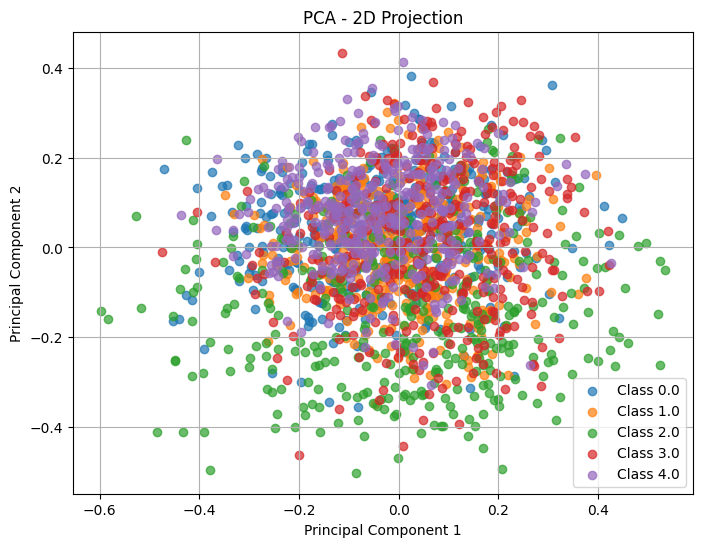

Training: (1999, 18) (1999,)
Validation: (499, 18) (499,)
Testing: (499, 18) (499,)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
path = "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2/"

X_train = pd.read_csv(path + "train_data.csv").values.astype(float)
y_train = pd.read_csv(path + "train_label.csv").values.ravel()

X_dev = pd.read_csv(path + "val_data.csv").values.astype(float)
y_dev = pd.read_csv(path + "val_label.csv").values.ravel()

X_test = pd.read_csv(path + "test_data.csv").values.astype(float)
y_test = pd.read_csv(path + "test_label.csv").values.ravel()

pca = PCA(k=18)
pca.fit(X_train)
X_train = pca.transform(X_train)
X_dev = pca.transform(X_dev)
X_test = pca.transform(X_test)
pca.plot_pca_2d(X_train, y_train)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_dev.shape, y_dev.shape)
print("Testing:", X_test.shape, y_test.shape)


Validation Results
Validation Accuracy: 0.5791583166332666
Confusion Matrix:
 [[35 18 13  8 25]
 [24 58  5  1 12]
 [10  5 73  8  4]
 [ 4  5 12 73  6]
 [28 17  2  3 50]]


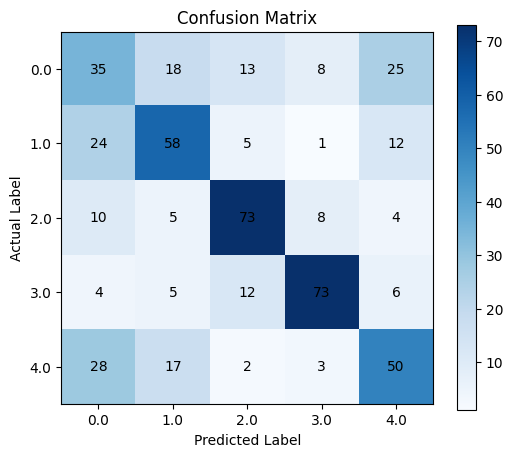

Accuracy: 0.5791583166332666

Testing Results
Confusion Matrix:
 [[41 19 13  9 17]
 [17 60 14  2  7]
 [ 7  8 77  5  3]
 [ 4  4 11 77  4]
 [30 15  9  2 44]]


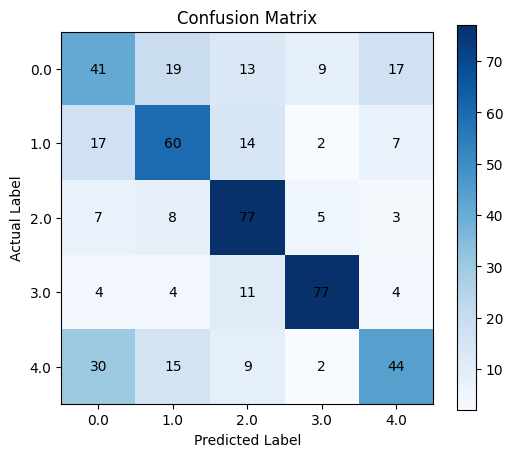

Accuracy: 0.5991983967935872
Plotting requires exactly 2 features.


In [13]:
model = GMMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5490981963927856
Confusion Matrix:
 [[41 20 10  6 22]
 [25 47 10  5 13]
 [ 3 16 64 14  3]
 [ 4  7 20 59 10]
 [20 11  3  3 63]]


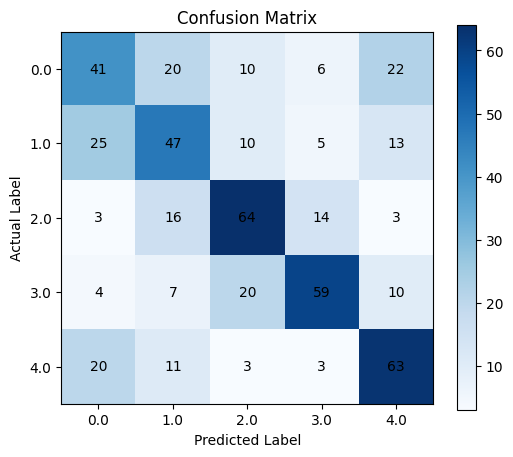

Accuracy: 0.5490981963927856

Testing Results
Confusion Matrix:
 [[24 28  9  5 33]
 [19 54 13  4 10]
 [ 7  9 67 12  5]
 [ 3  3 23 65  6]
 [20 17  4  2 57]]


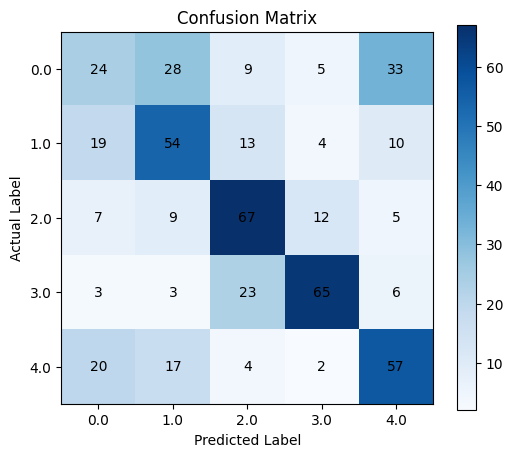

Accuracy: 0.5350701402805611


array([[24, 28,  9,  5, 33],
       [19, 54, 13,  4, 10],
       [ 7,  9, 67, 12,  5],
       [ 3,  3, 23, 65,  6],
       [20, 17,  4,  2, 57]])

In [14]:
model = LDAClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)



Validation Results
Validation Accuracy: 0.5410821643286573
Confusion Matrix:
 [[39 43  2  4 11]
 [18 73  1  1  7]
 [15 27 50  7  1]
 [11 17  3 65  4]
 [27 28  1  1 43]]


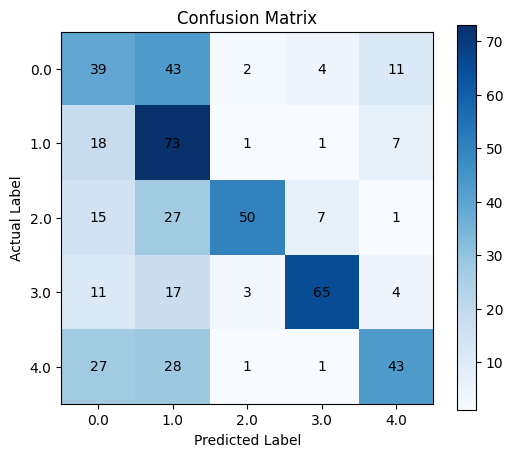

Accuracy: 0.5410821643286573

Testing Results
Confusion Matrix:
 [[36 38  6  3 16]
 [17 75  1  3  4]
 [12 22 49 11  6]
 [ 7 19  9 59  6]
 [29 36  1  0 34]]


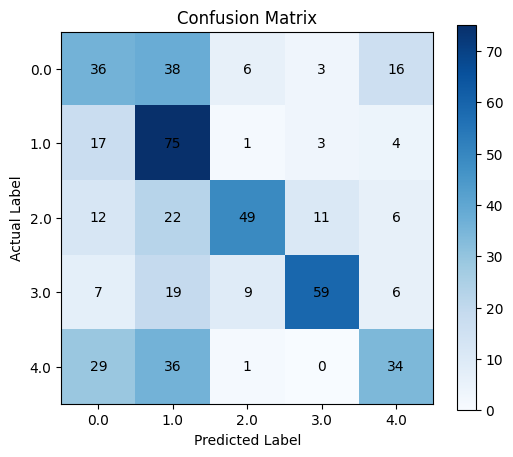

Accuracy: 0.5070140280561122


array([[36, 38,  6,  3, 16],
       [17, 75,  1,  3,  4],
       [12, 22, 49, 11,  6],
       [ 7, 19,  9, 59,  6],
       [29, 36,  1,  0, 34]])

In [15]:
model = KNNClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.5410821643286573
Confusion Matrix:
 [[31 21 12 10 25]
 [19 46 11  9 15]
 [ 1 16 66 14  3]
 [ 1  6 20 65  8]
 [10 14  3 11 62]]


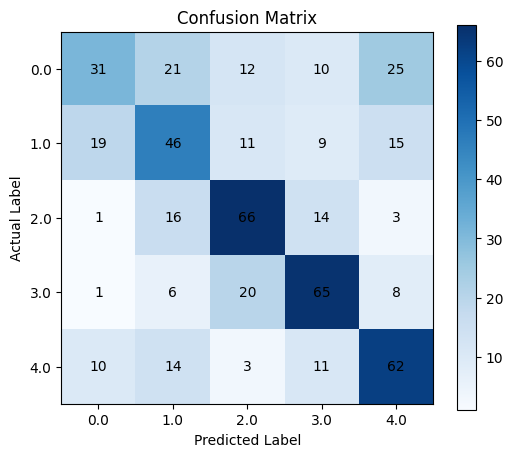

Accuracy: 0.5410821643286573

Testing Results
Confusion Matrix:
 [[20 23 12  9 35]
 [13 52 16  5 14]
 [ 4  9 67 15  5]
 [ 1  3 22 68  6]
 [15 14  5  7 59]]


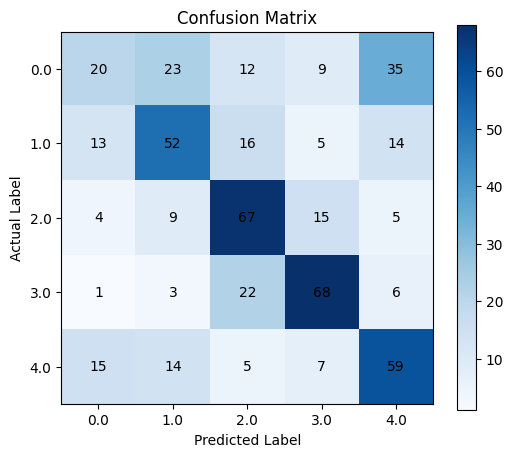

Accuracy: 0.533066132264529


array([[20, 23, 12,  9, 35],
       [13, 52, 16,  5, 14],
       [ 4,  9, 67, 15,  5],
       [ 1,  3, 22, 68,  6],
       [15, 14,  5,  7, 59]])

In [16]:
model = SVMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

##MNIST

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


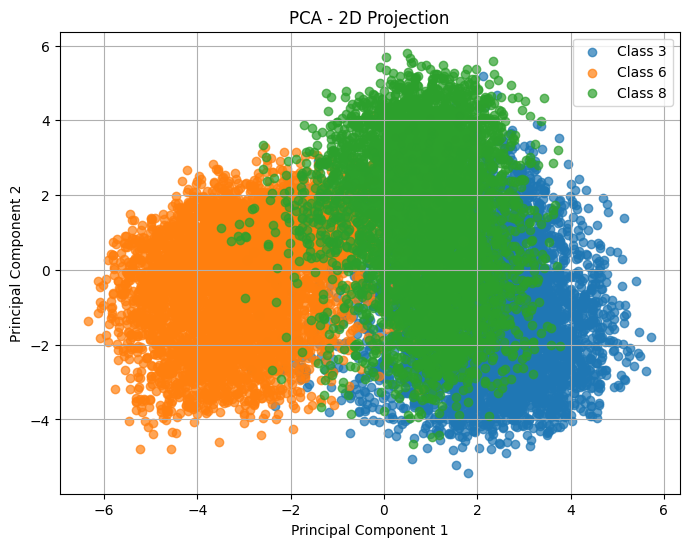

Training: (14312, 50) (14312,)
Development: (3588, 50) (3588,)
Testing: (2942, 50) (2942,)


In [18]:
import os
import numpy as np
from PIL import Image

from google.colab import drive
drive.mount('/content/drive')

base_path = "/content/drive/MyDrive/Krithik SNU/HAM/MNIST/Team 7"

digits = [3, 6, 8]

def load_split(split):

    X = []
    y = []

    for digit in digits:

        folder = os.path.join(base_path, split, str(digit))

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                img = Image.open(filepath).convert('L')
                img = img.resize((28, 28))

                img = np.asarray(img, dtype=float) / 255.0

                X.append(img.flatten())
                y.append(digit)

    return np.array(X), np.array(y)

X_train, y_train = load_split("train")
X_dev, y_dev = load_split("dev")
X_test, y_test = load_split("test")

pca = PCA(k=50)
pca.fit(X_train)
X_train = pca.transform(X_train)
X_dev = pca.transform(X_dev)
X_test = pca.transform(X_test)
pca.plot_pca_2d(X_train, y_train)

print("Training:", X_train.shape, y_train.shape)
print("Development:", X_dev.shape, y_dev.shape)
print("Testing:", X_test.shape, y_test.shape)

Validation Results
Validation Accuracy: 0.9832775919732442
Confusion Matrix:
 [[1215    0   30]
 [   3 1153   10]
 [  14    3 1160]]


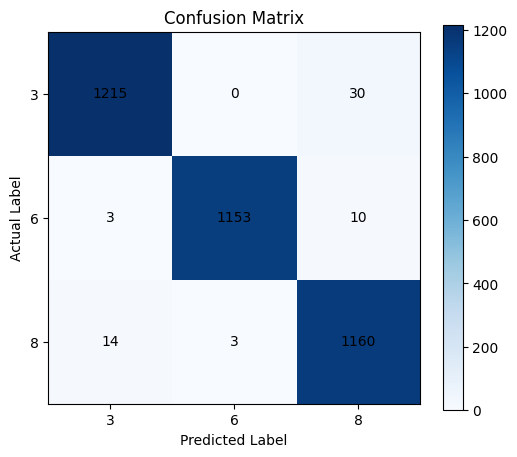

Accuracy: 0.9832775919732442
Testing Results
Confusion Matrix:
 [[990   0  20]
 [  1 943  14]
 [  9   1 964]]


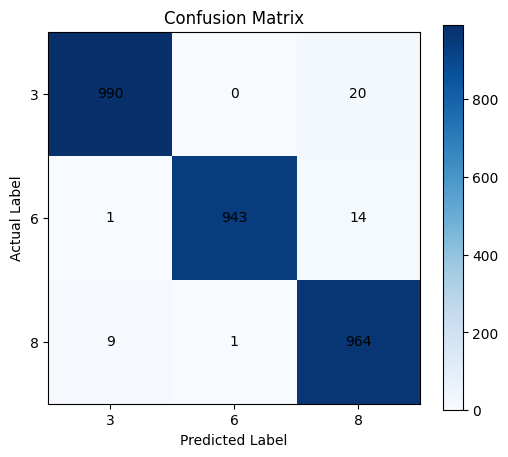

Accuracy: 0.9847042828008158


array([[990,   0,  20],
       [  1, 943,  14],
       [  9,   1, 964]])

In [19]:
model = GMMClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

Validation Results
Validation Accuracy: 0.9548494983277592
Confusion Matrix:
 [[1176   23   46]
 [   3 1137   26]
 [  46   18 1113]]


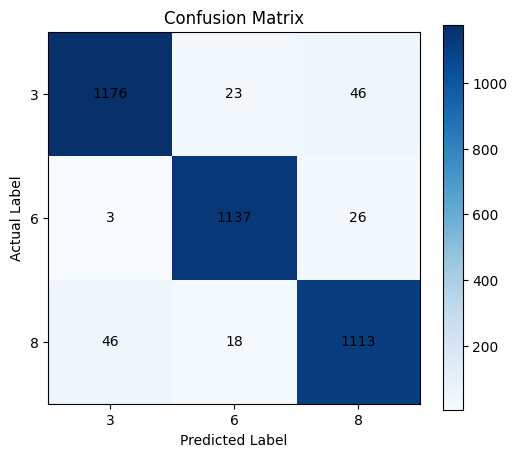

Accuracy: 0.9548494983277592
Testing Results
Confusion Matrix:
 [[969  10  31]
 [  3 940  15]
 [ 35  15 924]]


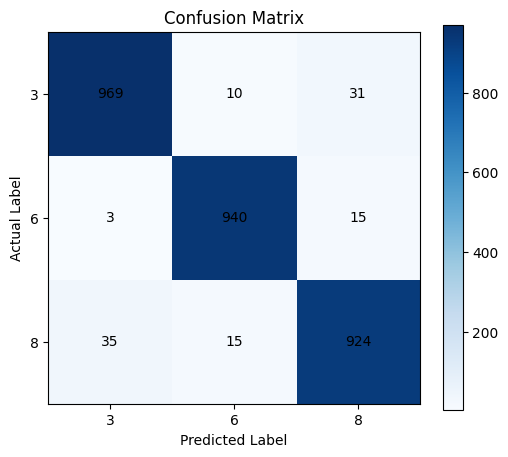

Accuracy: 0.9629503738953094


array([[969,  10,  31],
       [  3, 940,  15],
       [ 35,  15, 924]])

In [20]:
model = LDAClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

Validation Results
Validation Accuracy: 0.9888517279821628
Confusion Matrix:
 [[1230    2   13]
 [   2 1164    0]
 [  17    6 1154]]


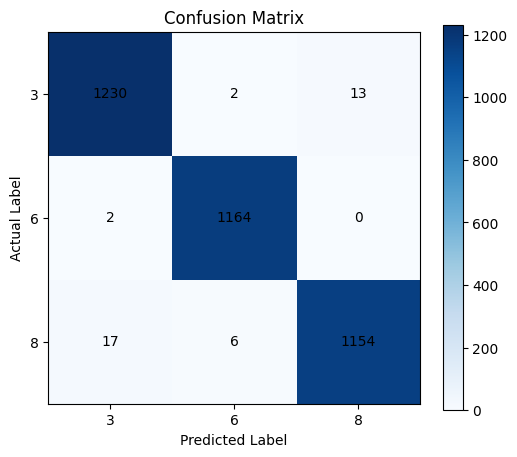

Accuracy: 0.9888517279821628
Testing Results
Confusion Matrix:
 [[999   0  11]
 [  0 957   1]
 [ 19   3 952]]


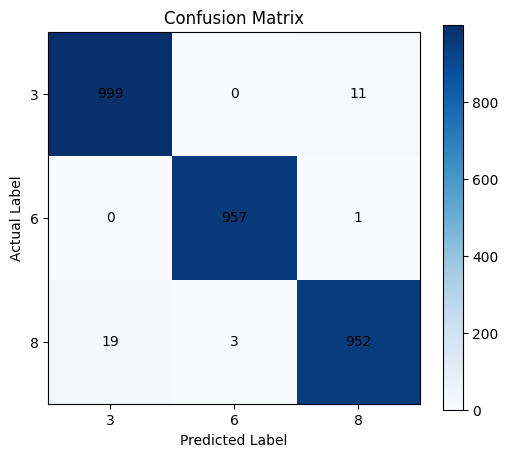

Accuracy: 0.9884432358939497


array([[999,   0,  11],
       [  0, 957,   1],
       [ 19,   3, 952]])

In [21]:
model = KNNClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

Validation Results
Validation Accuracy: 0.9545707915273133
Confusion Matrix:
 [[1180   22   43]
 [   5 1143   18]
 [  53   22 1102]]


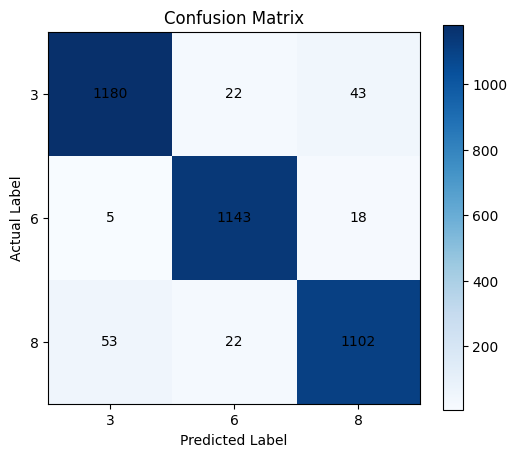

Accuracy: 0.9545707915273133
Testing Results
Confusion Matrix:
 [[965  13  32]
 [  4 942  12]
 [ 43  18 913]]


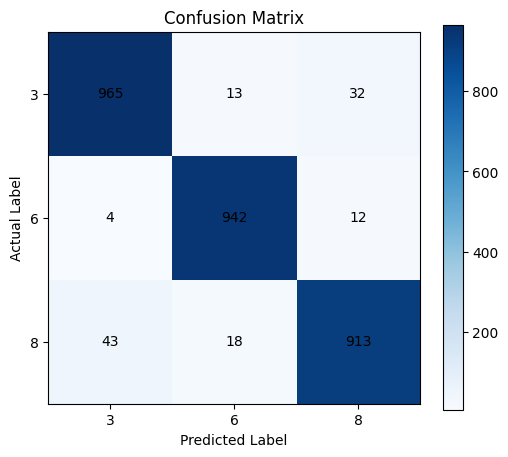

Accuracy: 0.9585316111488783


array([[965,  13,  32],
       [  4, 942,  12],
       [ 43,  18, 913]])

In [22]:
model = SVMClassifier()

model.fit(X_train, y_train)

print("Validation Results")
model.validate(X_dev, y_dev)

print("Testing Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

##TIDIGTS


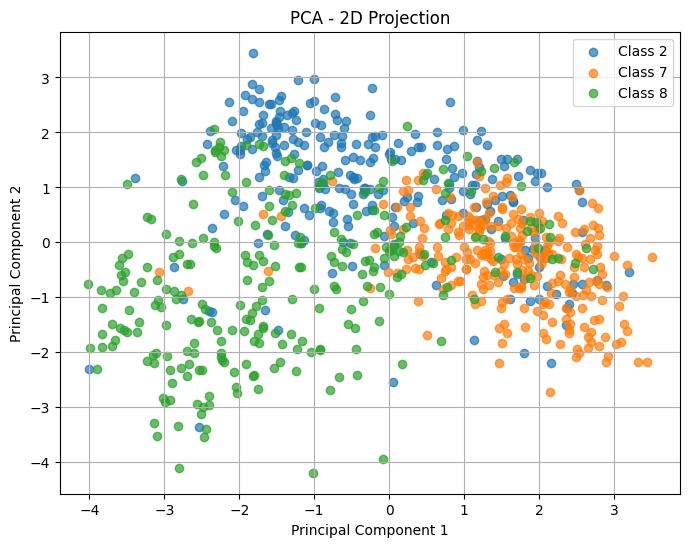

In [24]:
sequences = []
labels = []
for digit in [8, 7, 2]:
    with np.load(f"/content/drive/MyDrive/Krithik SNU/HAM/TIDigits/{digit}.npz") as data:
        for key in data.files:
            sequences.append(data[key])
            labels.append(digit)

X = []
for sequence in sequences:
    parts = np.array_split(sequence, 4)
    means = [part.mean(axis=0) for part in parts]
    X.append(np.concatenate(means))
X = np.array(X)
y = np.array(labels)
X_train, X_dev, X_test, y_train, y_dev, y_test = split_data(X,y)

pca = PCA(k=39)
pca.fit(X_train)
X_train = pca.transform(X_train)
X_dev = pca.transform(X_dev)
X_test = pca.transform(X_test)
pca.plot_pca_2d(X_train, y_train)


Validation Results
Validation Accuracy: 0.9888888888888889
Confusion Matrix:
 [[89  1  0]
 [ 1 89  0]
 [ 0  1 89]]


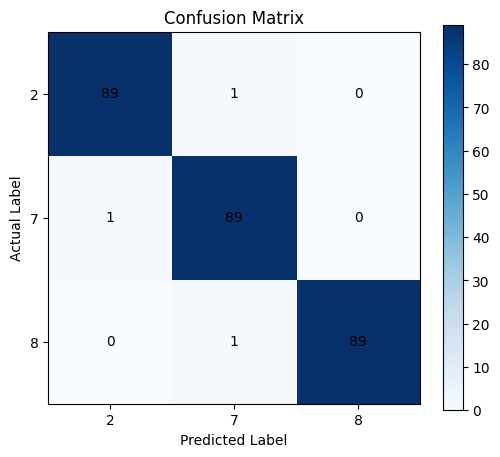

Accuracy: 0.9888888888888889

Testing Results
Confusion Matrix:
 [[86  1  3]
 [ 0 89  1]
 [ 0  0 90]]


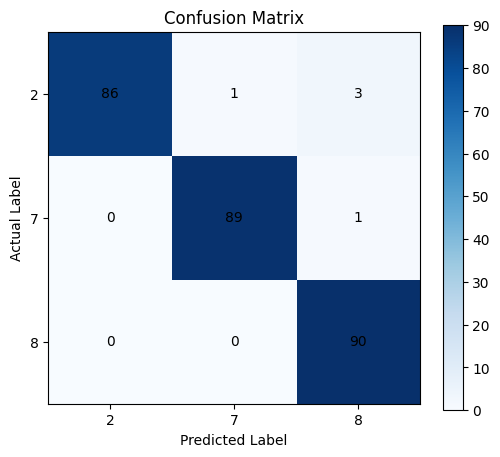

Accuracy: 0.9814814814814815


array([[86,  1,  3],
       [ 0, 89,  1],
       [ 0,  0, 90]])

In [25]:
model = GMMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.9777777777777777
Confusion Matrix:
 [[86  2  2]
 [ 1 88  1]
 [ 0  0 90]]


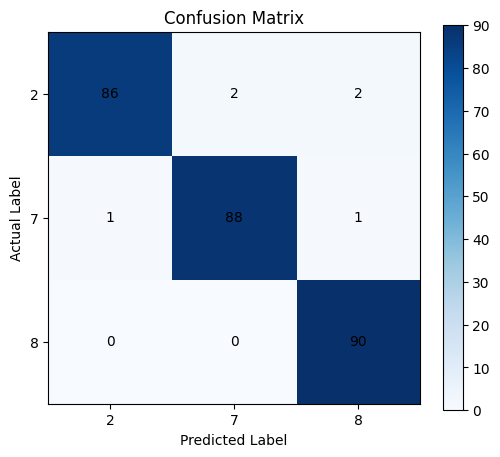

Accuracy: 0.9777777777777777

Testing Results
Confusion Matrix:
 [[81  5  4]
 [ 0 88  2]
 [ 2  0 88]]


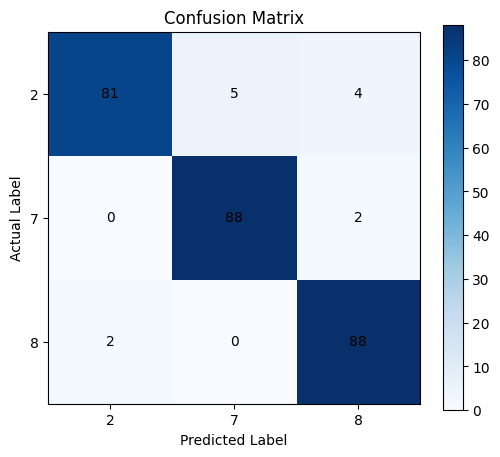

Accuracy: 0.9518518518518518


array([[81,  5,  4],
       [ 0, 88,  2],
       [ 2,  0, 88]])

In [27]:
model = LDAClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.9888888888888889
Confusion Matrix:
 [[88  0  2]
 [ 0 89  1]
 [ 0  0 90]]


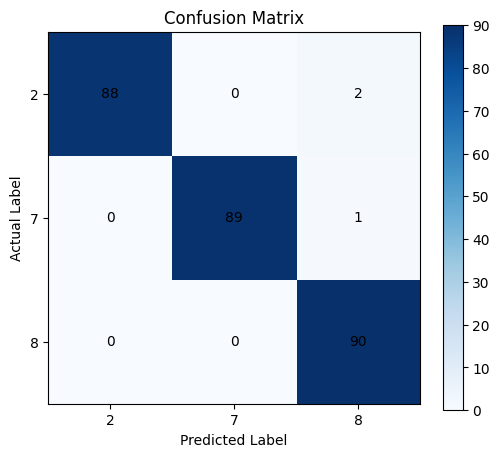

Accuracy: 0.9888888888888889

Testing Results
Confusion Matrix:
 [[87  1  2]
 [ 1 86  3]
 [ 0  0 90]]


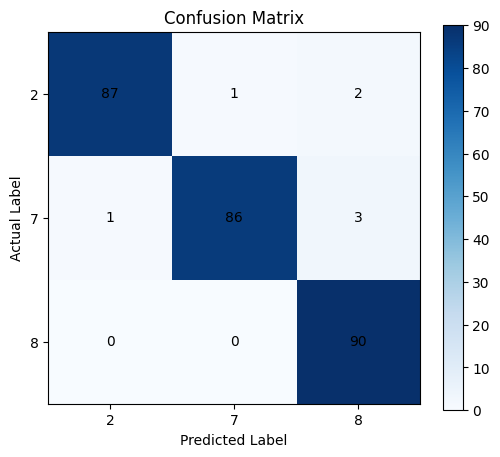

Accuracy: 0.9740740740740741


array([[87,  1,  2],
       [ 1, 86,  3],
       [ 0,  0, 90]])

In [28]:
model = KNNClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)


Validation Results
Validation Accuracy: 0.9740740740740741
Confusion Matrix:
 [[84  3  3]
 [ 0 89  1]
 [ 0  0 90]]


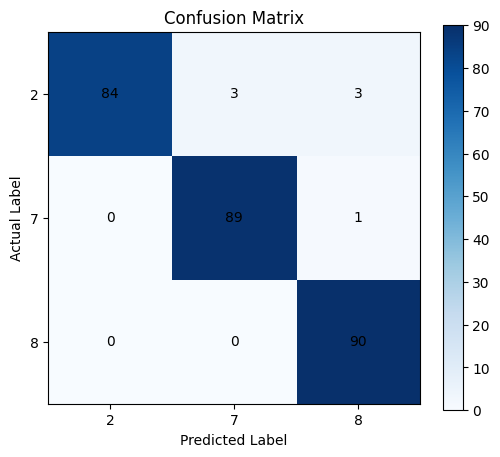

Accuracy: 0.9740740740740741

Testing Results
Confusion Matrix:
 [[79  7  4]
 [ 0 88  2]
 [ 1  0 89]]


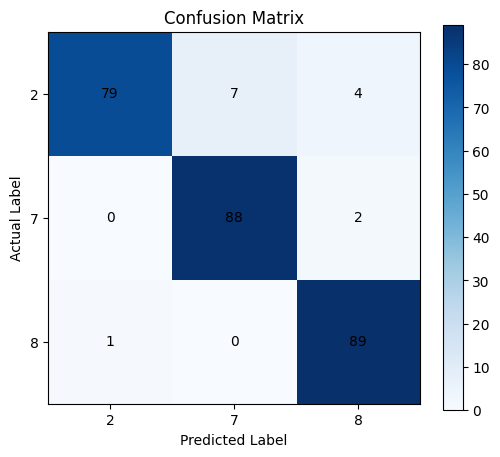

Accuracy: 0.9481481481481482


array([[79,  7,  4],
       [ 0, 88,  2],
       [ 1,  0, 89]])

In [29]:
model = SVMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)

##Image


In [ ]:
!echo "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2"
!ls "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2"

/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2
test_data.csv	train_data.csv	 val_data.csv
test_label.csv	train_label.csv  val_label.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


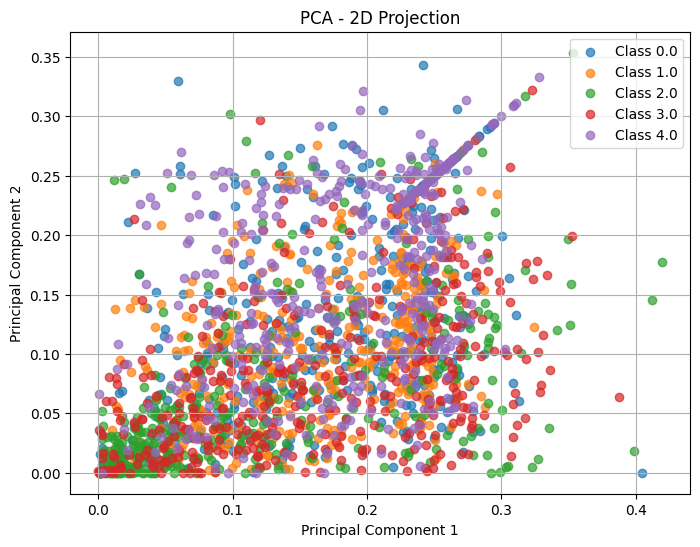

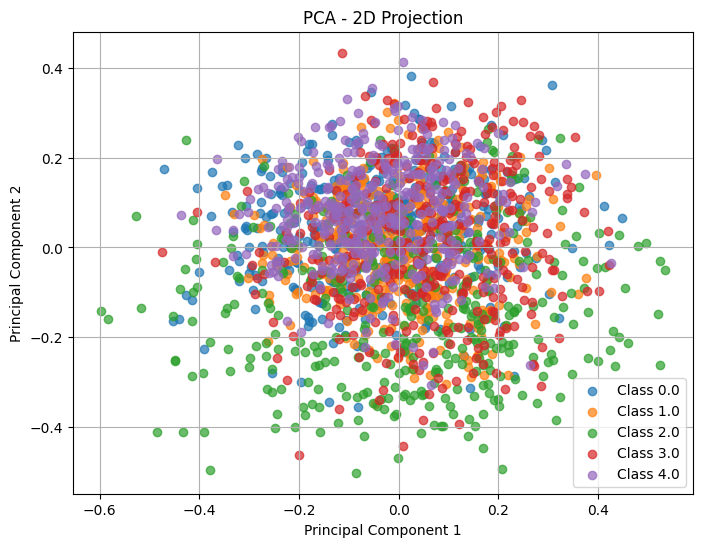

Training: (1999, 18) (1999,)
Development: (499, 18) (499,)
Testing: (499, 18) (499,)
Classes: [0. 1. 2. 3. 4.]


In [30]:

import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

base_path = "/content/drive/MyDrive/Krithik SNU/HAM/ImageFeatures/Dataset2/"

# Load training data
X_train = pd.read_csv(base_path + "train_data.csv").values.astype(float)
y_train = pd.read_csv(base_path + "train_label.csv").values.ravel()

# Load validation data
X_dev = pd.read_csv(base_path + "val_data.csv").values.astype(float)
y_dev = pd.read_csv(base_path + "val_label.csv").values.ravel()

# Load testing data
X_test = pd.read_csv(base_path + "test_data.csv").values.astype(float)
y_test = pd.read_csv(base_path + "test_label.csv").values.ravel()

pca = PCA(k=18)
pca.plot_pca_2d(X_train, y_train)
pca.fit(X_train)
X_train = pca.transform(X_train)
X_dev = pca.transform(X_dev)
X_test = pca.transform(X_test)
pca.plot_pca_2d(X_train, y_train)

print("Training:", X_train.shape, y_train.shape)
print("Development:", X_dev.shape, y_dev.shape)
print("Testing:", X_test.shape, y_test.shape)

print("Classes:", np.unique(y_train))



Validation Results
Validation Accuracy: 0.5791583166332666
Confusion Matrix:
 [[35 18 13  8 25]
 [24 58  5  1 12]
 [10  5 73  8  4]
 [ 4  5 12 73  6]
 [28 17  2  3 50]]


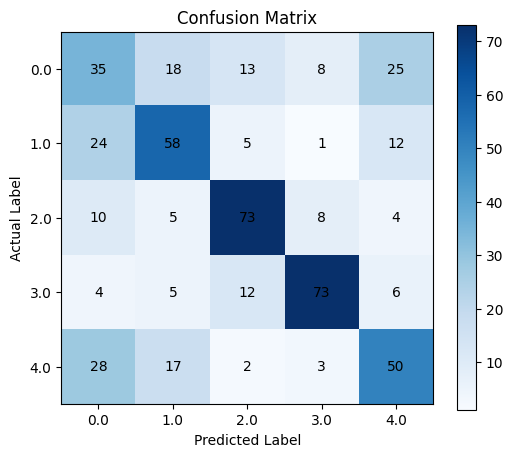

Accuracy: 0.5791583166332666

Testing Results
Confusion Matrix:
 [[41 19 13  9 17]
 [17 60 14  2  7]
 [ 7  8 77  5  3]
 [ 4  4 11 77  4]
 [30 15  9  2 44]]


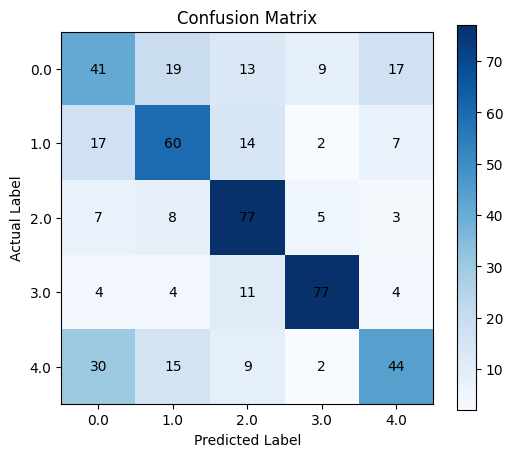

Accuracy: 0.5991983967935872
Plotting requires exactly 2 features.


In [31]:
model = GMMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5490981963927856
Confusion Matrix:
 [[41 20 10  6 22]
 [25 47 10  5 13]
 [ 3 16 64 14  3]
 [ 4  7 20 59 10]
 [20 11  3  3 63]]


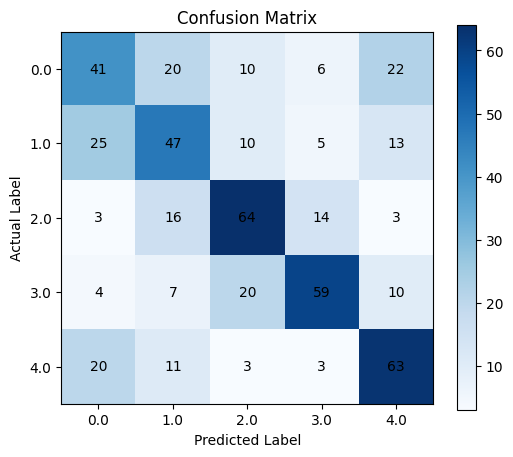

Accuracy: 0.5490981963927856

Testing Results
Confusion Matrix:
 [[24 28  9  5 33]
 [19 54 13  4 10]
 [ 7  9 67 12  5]
 [ 3  3 23 65  6]
 [20 17  4  2 57]]


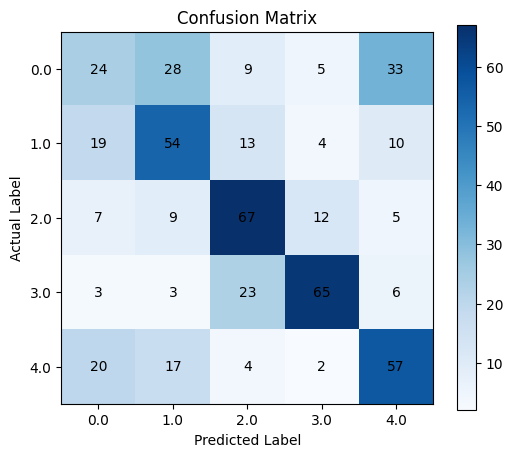

Accuracy: 0.5350701402805611
Plotting requires exactly 2 features.


In [32]:
model = LDAClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5410821643286573
Confusion Matrix:
 [[39 43  2  4 11]
 [18 73  1  1  7]
 [15 27 50  7  1]
 [11 17  3 65  4]
 [27 28  1  1 43]]


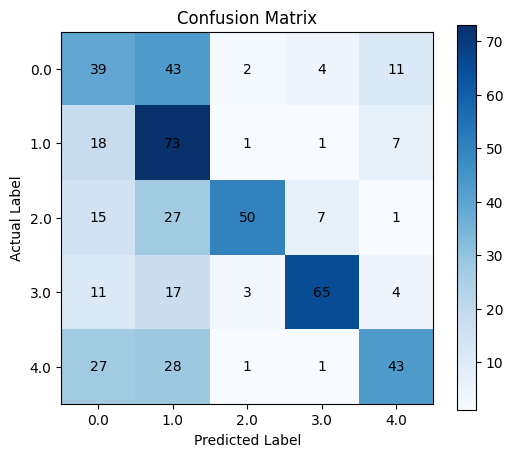

Accuracy: 0.5410821643286573

Testing Results
Confusion Matrix:
 [[36 38  6  3 16]
 [17 75  1  3  4]
 [12 22 49 11  6]
 [ 7 19  9 59  6]
 [29 36  1  0 34]]


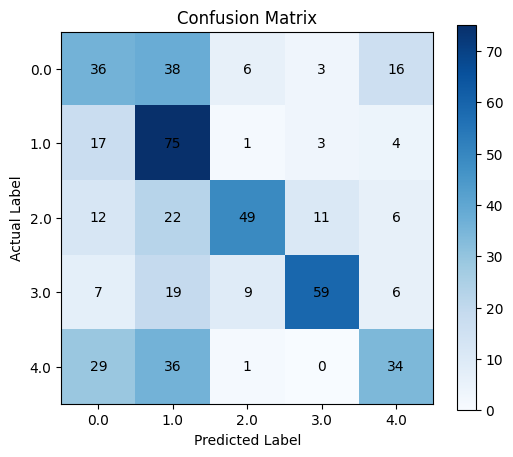

Accuracy: 0.5070140280561122
Plotting requires exactly 2 features.


In [33]:
model = KNNClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")


Validation Results
Validation Accuracy: 0.5410821643286573
Confusion Matrix:
 [[31 21 12 10 25]
 [19 46 11  9 15]
 [ 1 16 66 14  3]
 [ 1  6 20 65  8]
 [10 14  3 11 62]]


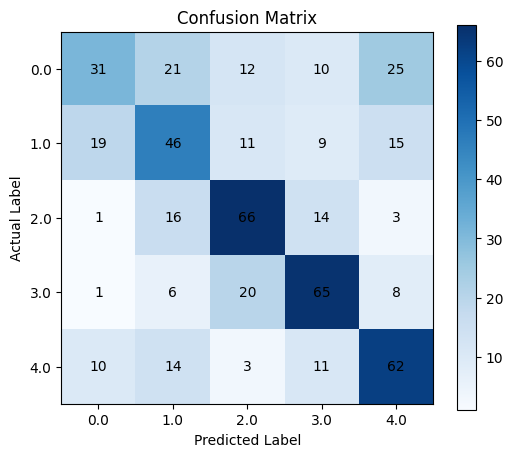

Accuracy: 0.5410821643286573

Testing Results
Confusion Matrix:
 [[20 23 12  9 35]
 [13 52 16  5 14]
 [ 4  9 67 15  5]
 [ 1  3 22 68  6]
 [15 14  5  7 59]]


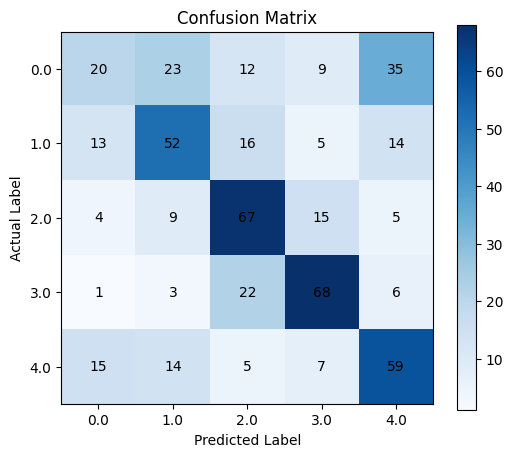

Accuracy: 0.533066132264529
Plotting requires exactly 2 features.


In [34]:
model = SVMClassifier()
model.fit(X_train, y_train)
print("\nValidation Results")
model.validate(X_dev, y_dev)

print("\nTesting Results")
y_pred = model.predict(X_test)

model.confusion_matrix(y_test, y_pred)
model.plot(X_test, y_test, "LDA Decision Boundary")